In [2]:
pip install pandas as pd

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement as (from versions: none)
ERROR: No matching distribution found for as


In [8]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
import pandas as pd

In [7]:
pip install --upgrade openpyxl

   ---------------------------------------- 0.0/250.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/250.9 kB ? eta -:--:--
   - -------------------------------------- 10.2/250.9 kB ? eta -:--:--
   - -------------------------------------- 10.2/250.9 kB ? eta -:--:--
   ------ -------------------------------- 41.0/250.9 kB 245.8 kB/s eta 0:00:01
   ------------ -------------------------- 81.9/250.9 kB 383.3 kB/s eta 0:00:01
   ----------------- -------------------- 112.6/250.9 kB 437.6 kB/s eta 0:00:01
   ------------------------ ------------- 163.8/250.9 kB 546.6 kB/s eta 0:00:01
   -------------------------- ----------- 174.1/250.9 kB 525.1 kB/s eta 0:00:01
   ---------------------------------- --- 225.3/250.9 kB 599.0 kB/s eta 0:00:01
   -------------------------------------- 250.9/250.9 kB 592.8 kB/s eta 0:00:00
  Attempting uninstall: openpyxl
    Found existing installation: openpyxl 3.0.10
    Uninstalling openpyxl-3.0.10:
      Successfully uninstalled openpyx

  You can safely remove it manually.


In [3]:
Pf = pd.read_excel('D:/AWMZ Library/Personal docs/CNST/SW_Data/Clean data/Daily_Prec.xlsx')

In [4]:
Pf.head()

,date,Precip_mm
0,1991-01-01,0
1,1991-01-02,0
2,1991-01-03,2.4
3,1991-01-04,5.1
4,1991-01-05,0


In [11]:
Pf['Precip_mm'] = Pf['Precip_mm'].replace('TR', 0)
Pf['Precip_mm'] = pd.to_numeric(Pf['Precip_mm'], errors='coerce')

C:\Users\JUSTUS\AppData\Local\Temp\ipykernel_18628\2992669146.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  Pf['Precip_mm'] = Pf['Precip_mm'].replace('TR', 0)


In [6]:
Pf['date'] = pd.to_datetime(Pf['date'])

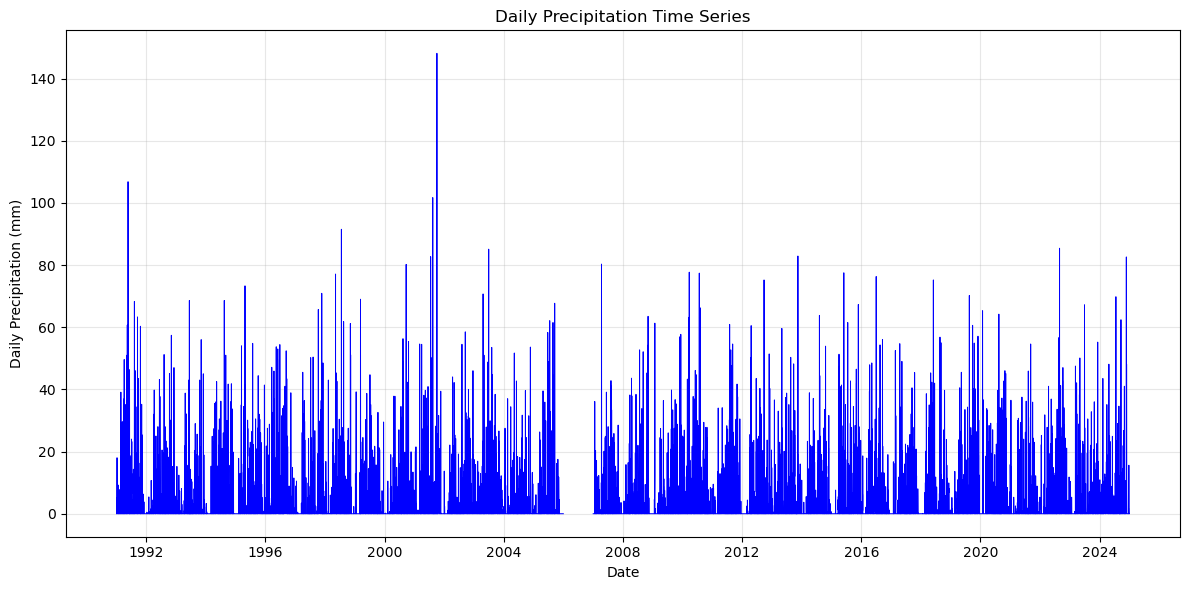

In [12]:
plt.figure(figsize=(12,6))
plt.plot(Pf['date'], Pf['Precip_mm'], color='blue', linewidth=0.7)

plt.xlabel("Date")
plt.ylabel("Daily Precipitation (mm)")
plt.title("Daily Precipitation Time Series")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [80]:
Pf.tail()

,date,Precip_mm
12410,2024-12-27,0.0
12411,2024-12-28,0.0
12412,2024-12-29,0.0
12413,2024-12-30,0.0
12414,2024-12-31,0.0


In [86]:
print(Pf.columns)`

Index(['Precip_mm'], dtype='object')


In [87]:
print(Pf.index)

DatetimeIndex(['1991-01-01', '1991-01-02', '1991-01-03', '1991-01-04',
               '1991-01-05', '1991-01-06', '1991-01-07', '1991-01-08',
               '1991-01-09', '1991-01-10',
               ...
               '2024-12-22', '2024-12-23', '2024-12-24', '2024-12-25',
               '2024-12-26', '2024-12-27', '2024-12-28', '2024-12-29',
               '2024-12-30', '2024-12-31'],
              dtype='datetime64[ns]', name='date', length=12415, freq=None)


In [88]:
# Step 1: Resample daily data into monthly totals
monthly_rain = Pf['Precip_mm'].resample('M').sum()

# Step 2: Compute the climatological mean for each month (1991–2025)
monthly_avg = monthly_rain.groupby(monthly_rain.index.month).mean()

# Step 3: Replace month numbers with names
monthly_avg.index = ['Jan','Feb','Mar','Apr','May','Jun',
                     'Jul','Aug','Sep','Oct','Nov','Dec']

print(monthly_avg)

Jan     37.355882
Feb     31.911765
Mar     85.364706
Apr    161.885294
May    165.567647
Jun    111.200000
Jul    114.717647
Aug    164.767647
Sep    140.188235
Oct    149.041176
Nov    107.976471
Dec     41.447059
Name: Precip_mm, dtype: float64


C:\Users\JUSTUS\AppData\Local\Temp\ipykernel_18628\3312313439.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_rain = Pf['Precip_mm'].resample('M').sum()


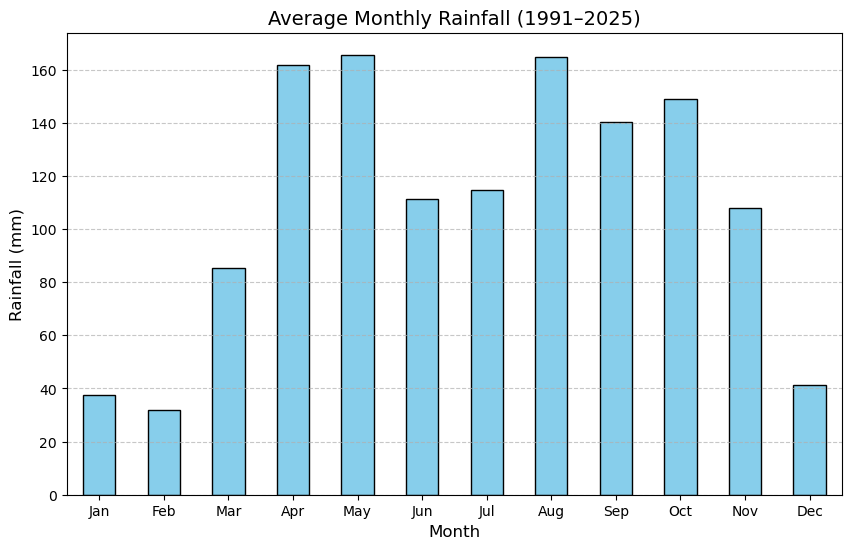

In [89]:

# Assuming you already calculated monthly_avg
plt.figure(figsize=(10,6))
monthly_avg.plot(kind='bar', color='skyblue', edgecolor='black')

plt.title('Average Monthly Rainfall (1991–2025)', fontsize=14)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Rainfall (mm)', fontsize=12)
plt.xticks(rotation=0)   # keep month labels horizontal
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

In [9]:
Pf.set_index('date', inplace=True)

In [14]:
Pf['Precip_mm'] = pd.to_numeric(Pf['Precip_mm'], errors='coerce')

In [15]:
monthly_precip = Pf['Precip_mm'].resample('M').sum()

In [32]:
monthly_precip_df = monthly_precip.to_frame()

In [34]:
monthly_precip_df.head()

,Precip_mm
date,
1991-01-31,56.2
1991-02-28,57.9
1991-03-31,79.0
1991-04-30,181.6
1991-05-31,430.0


In [17]:
Et = pd.read_excel('D:/AWMZ Library/Personal docs/CNST/SW_Data/Clean data/ClimateEngine_monthly.xlsx')

In [18]:
Et.head()

,Actual ET (TerraClimate),Unnamed: 1
0,Date,ET (mm)
1,1990-01-01,41.0853
2,1990-02-01,110.1402
3,1990-03-01,124.1307
4,1990-04-01,121.0058


In [24]:
monthly_precip = monthly_precip.rename("Precip_mm")
monthly_precip_df = monthly_precip.to_frame()

In [39]:
monthly_precip_df.tail()

,Precip_mm
date,
2024-08-31,110.7
2024-09-30,122.2
2024-10-31,144.7
2024-11-30,187.4
2024-12-31,23.5


In [25]:
monthly_precip.set_index('date', inplace=True)

AttributeError: 'Series' object has no attribute 'set_index'

In [38]:
monthly_precip_df.to_excel('D:/AWMZ Library/Personal docs/CNST/SW_Data/Clean data/Monthly_Prec.xlsx', index=False)

In [15]:
CD = pd.read_excel('D:/AWMZ Library/Personal docs/CNST/SW_Data/Clean data/Monthly ET, Prec, Q.xlsx')

In [17]:
C

,Time,Evapotranspiration,Precipitation,Monthly Discharge
0,1990-01,41.0853,NaN,NaN
1,1990-02,110.1402,NaN,NaN
2,1990-03,124.1307,NaN,NaN
3,1990-04,121.0058,NaN,NaN
4,1990-05,126.8771,NaN,NaN
...,...,...,...,...
423,2025-04,NaN,NaN,668.625
424,2025-05,NaN,NaN,688.069
425,2025-06,NaN,NaN,676.356
426,2025-07,NaN,NaN,736.971


In [19]:
print(Pf.columns)

Index(['date', 'Precip_mm'], dtype='object')


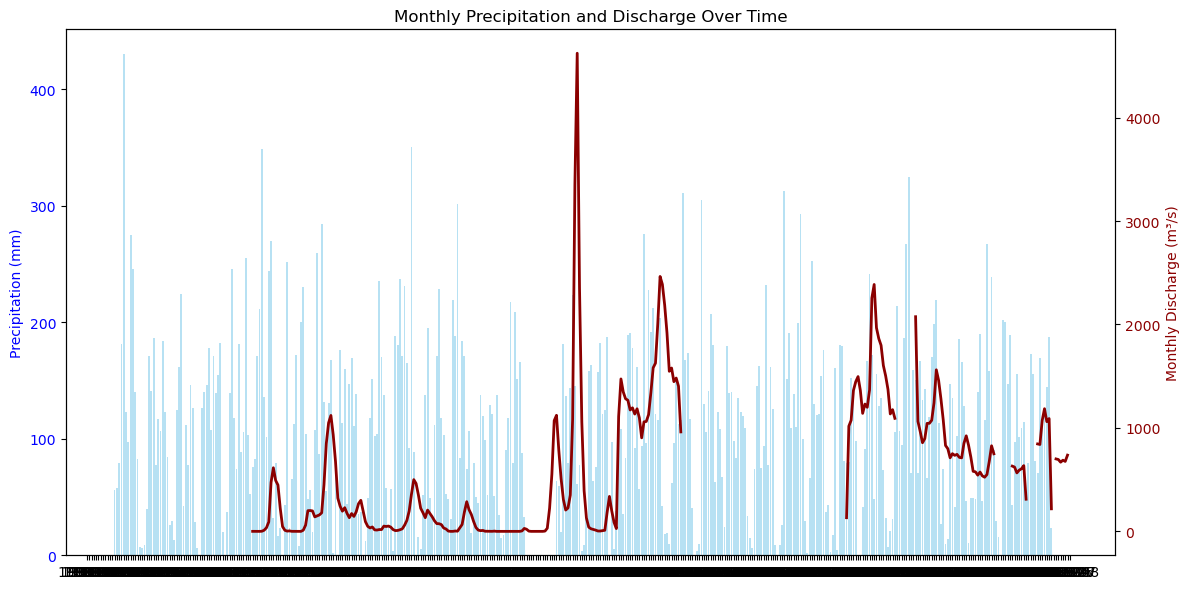

In [20]:
fig, ax1 = plt.subplots(figsize=(12,6))

# --- Precipitation as bar chart ---
ax1.bar(CD['Time'], CD['Precipitation'], 
        color='skyblue', alpha=0.6, label="Precipitation")
ax1.set_ylabel("Precipitation (mm)", color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# --- Discharge as line chart ---
ax2 = ax1.twinx()
ax2.plot(CD['Time'], CD['Monthly Discharge'], 
         color='darkred', linewidth=2, label="Discharge")
ax2.set_ylabel("Monthly Discharge (m³/s)", color='darkred')
ax2.tick_params(axis='y', labelcolor='darkred')

# --- Formatting ---
plt.title("Monthly Precipitation and Discharge Over Time")
fig.tight_layout()
plt.show()

Monthly Water Balance computation  ΔS=P−(ET+Q)

In [6]:
##ΔS=P−(ET+Q) 

In [95]:
df = pd.DataFrame(CD)

In [96]:
df['Delta_Storage'] = df['Precipitation'] - (df['Evapotranspiration'] + df['Monthly Discharge'])

Inspect for spaces in column names 

In [97]:
print(df.columns.tolist())

['Time', 'Evapotranspiration', 'Precipitation', 'Monthly Discharge', 'Delta_Storage']


strip spaces from column names

In [98]:
df.columns = df.columns.str.strip()
print(df.columns.tolist())

['Time', 'Evapotranspiration', 'Precipitation', 'Monthly Discharge', 'Delta_Storage']


In [99]:
df['Delta_Storage'] = df['Precipitation'] - (df['Evapotranspiration'] + df['Monthly Discharge'])
df['Cumulative_Storage'] = df['Delta_Storage'].cumsum()

In [100]:
df.tail()

,Time,Evapotranspiration,Precipitation,Monthly Discharge,Delta_Storage,Cumulative_Storage
423,2025-04,NaN,NaN,668.625,NaN,NaN
424,2025-05,NaN,NaN,688.069,NaN,NaN
425,2025-06,NaN,NaN,676.356,NaN,NaN
426,2025-07,NaN,NaN,736.971,NaN,NaN
427,2025-08,NaN,NaN,NaN,NaN,NaN


In [101]:
df_clean = df.dropna(subset=['Precipitation', 'Evapotranspiration', 'Monthly Discharge'])

In [102]:
df_clean

,Time,Evapotranspiration,Precipitation,Monthly Discharge,Delta_Storage,Cumulative_Storage
72,1996-01,75.6758,76.0,0.257,0.0672,0.0672
73,1996-02,73.5825,82.7,0.067,9.0505,9.1177
74,1996-03,92.5008,171.4,0.000,78.8992,88.0169
75,1996-04,126.9869,211.5,0.009,84.5041,172.5210
76,1996-05,119.2640,349.0,1.280,228.4560,400.9770
...,...,...,...,...,...,...
415,2024-08,126.7516,110.7,1071.922,-1087.9736,-142133.0249
416,2024-09,127.8778,122.2,1185.654,-1191.3318,-143324.3567
417,2024-10,132.0786,144.7,1060.544,-1047.9226,-144372.2793
418,2024-11,117.0672,187.4,1090.328,-1019.9952,-145392.2745


In [103]:
df['Time'] = pd.to_datetime(df['Time'], format='%Y-%m')

In [107]:
df.head()

,Time,Evapotranspiration,Precipitation,Monthly Discharge,Delta_Storage,Cumulative_Storage
0,1990-01-01,41.0853,NaN,NaN,NaN,NaN
1,1990-02-01,110.1402,NaN,NaN,NaN,NaN
2,1990-03-01,124.1307,NaN,NaN,NaN,NaN
3,1990-04-01,121.0058,NaN,NaN,NaN,NaN
4,1990-05-01,126.8771,NaN,NaN,NaN,NaN


In [111]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
plt.figure(figsize=(12, 6))
import matplotlib.dates as mdates

<Figure size 1200x600 with 0 Axes>

AttributeError: module 'matplotlib.pyplot' has no attribute 'yaxis'

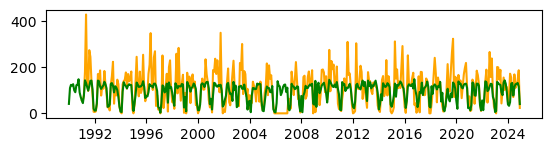

In [114]:
plt.subplot(3, 1, 1)
ax1.plot(df['Time'], df['Precipitation'], label='Precipitation', color='orange')
ax1.plot(df['Time'], df['Evapotranspiration'], label='Evapotranspiration', color='green')
ax1.set_ylabel('Precipitation & ET (mm/month)')
ax1.legend(loc='upper left')
plt.plot(df['Time'], df['Precipitation'], label='Precipitation', color='orange')
plt.plot(df['Time'], df['Evapotranspiration'], label='Evapotranspiration', color='green')
plt.yaxis.set_major_locator(MultipleLocator(50))
plt.legend()
plt.title('Catchment Water Balance Components')
plt.ylabel('mm/month')

NameError: name 'df' is not defined

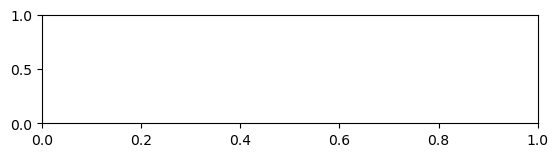

In [13]:
ax1 = plt.subplot(3, 1, 1)
ax1.plot(df['Time'], df['Precipitation'], label='Precipitation', color='orange')
ax1.plot(df['Time'], df['Evapotranspiration'], label='Evapotranspiration', color='green')
ax1.set_ylabel('Precipitation & ET (mm/month)')
ax1.legend(loc='upper left')

ax2 = ax1.twinx()
ax2.plot(df['Time'], df['Monthly Discharge'], label='Discharge', color='blue')
ax2.set_ylabel('Discharge (m3/month)')
ax2.legend(loc='upper right')
ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=24))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y')) # Format the ticks to show only the year
plt.xticks(rotation=90, ha='right')




NameError: name 'df' is not defined

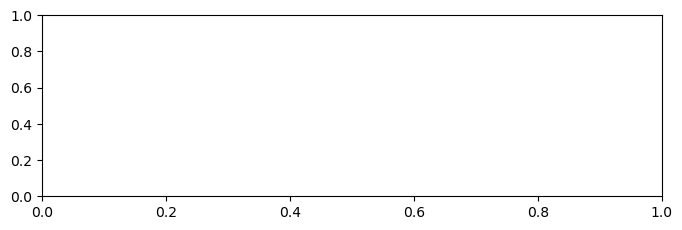

In [93]:
plt.figure(figsize=(8, 8))
ax1 = plt.subplot(3, 1, 1)
ax1.plot(df['Time'], df['Precipitation'], label='Precipitation', color='orange')
ax1.plot(df['Time'], df['Evapotranspiration'], label='Evapotranspiration', color='green')
ax1.set_ylabel('Precipitation & ET (mm/month)')
ax1.legend(loc='upper left')
ax1.xaxis.set_major_locator(mdates.YearLocator(2))   # tick every 2 years
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.xticks(rotation=45)


ax2.plot(df['Time'], df['Monthly Discharge'], label='Discharge', color='blue')
ax2.set_ylabel('Discharge (mm/month)')
ax2.legend(loc='upper right')


ax2.yaxis.set_major_locator(MultipleLocator(500))
ax1.yaxis.set_major_locator(MultipleLocator(50))


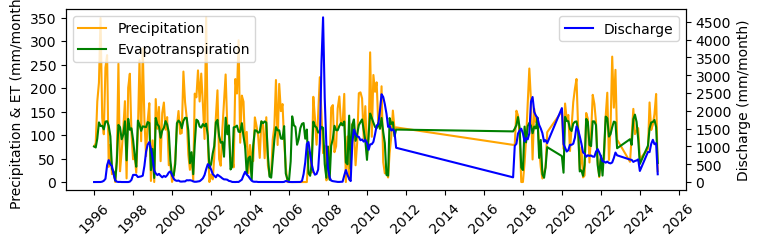

In [112]:
plt.figure(figsize=(8, 8))
ax1 = plt.subplot(3, 1, 1)
ax1.plot(df['Time'], df['Precipitation'], label='Precipitation', color='orange')
ax1.plot(df['Time'], df['Evapotranspiration'], label='Evapotranspiration', color='green')
ax1.set_ylabel('Precipitation & ET (mm/month)')
ax1.legend(loc='upper left')
ax1.xaxis.set_major_locator(mdates.YearLocator(2))   # tick every 2 years
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.xticks(rotation=45)

ax2 = ax1.twinx()
ax2.plot(df['Time'], df['Monthly Discharge'], label='Discharge', color='blue')
ax2.set_ylabel('Discharge (mm/month)')
ax2.legend(loc='upper right')


ax2.yaxis.set_major_locator(MultipleLocator(500))
ax1.yaxis.set_major_locator(MultipleLocator(50))


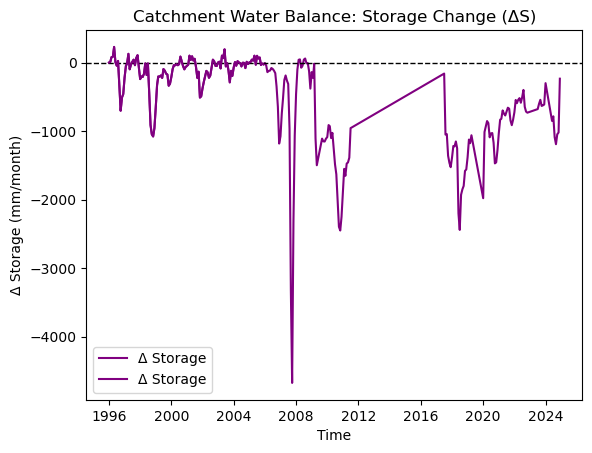

In [121]:
plt.plot(df['Time'], df['Delta_Storage'], color='purple', linewidth=1.5, label='Δ Storage')

plt.axhline(0, color='black', linestyle='--', linewidth=1)  # zero reference line
df_filtered = df[df['Time'] <= '2005-12-31']
plt.plot(df_filtered['Time'], df_filtered['Delta_Storage'], 
         color='purple', linewidth=1.5, label='Δ Storage')

plt.xlabel("Time")
plt.ylabel("Δ Storage (mm/month)")
plt.title("Catchment Water Balance: Storage Change (ΔS)")
plt.legend()

C:\Users\JUSTUS\AppData\Local\Temp\ipykernel_29112\2165949085.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['Month'] = df_filtered['Time'].dt.month


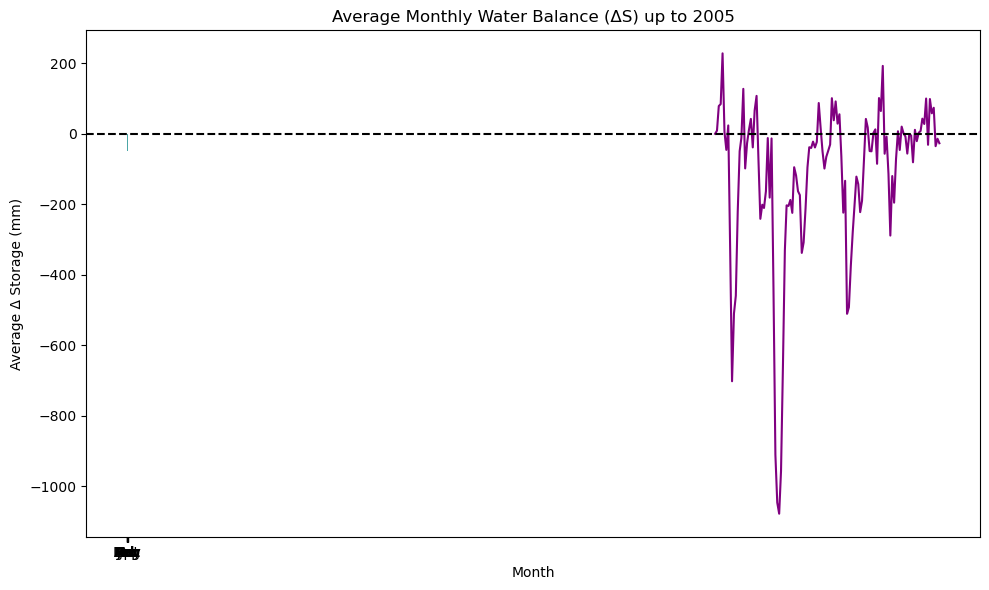

In [119]:
df_filtered = df[df['Time'] <= '2005-12-31']
plt.figure(figsize=(10,6))
plt.plot(df_filtered['Time'], df_filtered['Delta_Storage'], 
         color='purple', linewidth=1.5, label='Δ Storage')



In [23]:
A = pd.read_excel('D:/AWMZ Library/Personal docs/CNST/SW_Data/Clean data/Awoja WL.xlsx')

In [25]:
A

,Date,WL (m)
0,1958-12-16,8.86
1,1958-12-16,8.86
2,1958-12-17,8.86
3,1958-12-17,8.86
4,1958-12-18,8.89
...,...,...
48665,2025-07-29,9.11
48666,2025-07-30,9.11
48667,2025-07-30,9.11
48668,2025-07-31,9.11


In [26]:
AD = A.groupby("Date", as_index=False)["WL (m)"].mean()

In [27]:
AD

,Date,WL (m)
0,1958-12-16,8.86
1,1958-12-17,8.86
2,1958-12-18,8.89
3,1958-12-19,8.89
4,1958-12-20,8.89
...,...,...
24330,2025-07-27,9.12
24331,2025-07-28,9.11
24332,2025-07-29,9.11
24333,2025-07-30,9.11


In [28]:
AD.to_excel("D:/AWMZ Library/Personal docs/CNST/SW_Data/Daily_WaterLevel.xlsx", index=False)

In [35]:
B = pd.read_excel('D:/AWMZ Library/Personal docs/CNST/SW_Data/Bugondo.xlsx')

In [36]:
B.head()

,Date,Water level
0,1948-01-01,11.08
1,1948-01-01,11.06
2,1948-01-02,11.07
3,1948-01-02,11.07
4,1948-01-03,11.06


In [37]:
AB = B.groupby("Date", as_index=False)["Water level"].mean()

In [38]:
AB.head()

,Date,Water level
0,1948-01-01,11.070
1,1948-01-02,11.070
2,1948-01-03,11.070
3,1948-01-04,11.075
4,1948-01-05,11.095


In [39]:
AB.to_excel("D:/AWMZ Library/Personal docs/CNST/SW_Data/Bugondo Daily_WL.xlsx", index=False)

In [42]:
Bu = pd.read_excel('D:/AWMZ Library/Personal docs/CNST/SW_Data/Bugondo Daily_WL.xlsx')

In [43]:
Bu.head()

,Date,Water level(m),Rainfall (mm)
0,1948-01-01,11.070,NaN
1,1948-01-02,11.070,NaN
2,1948-01-03,11.070,NaN
3,1948-01-04,11.075,NaN
4,1948-01-05,11.095,NaN


In [45]:
Bu['Rainfall (mm)'] = pd.to_numeric(Bu['Rainfall (mm)'], errors='coerce')

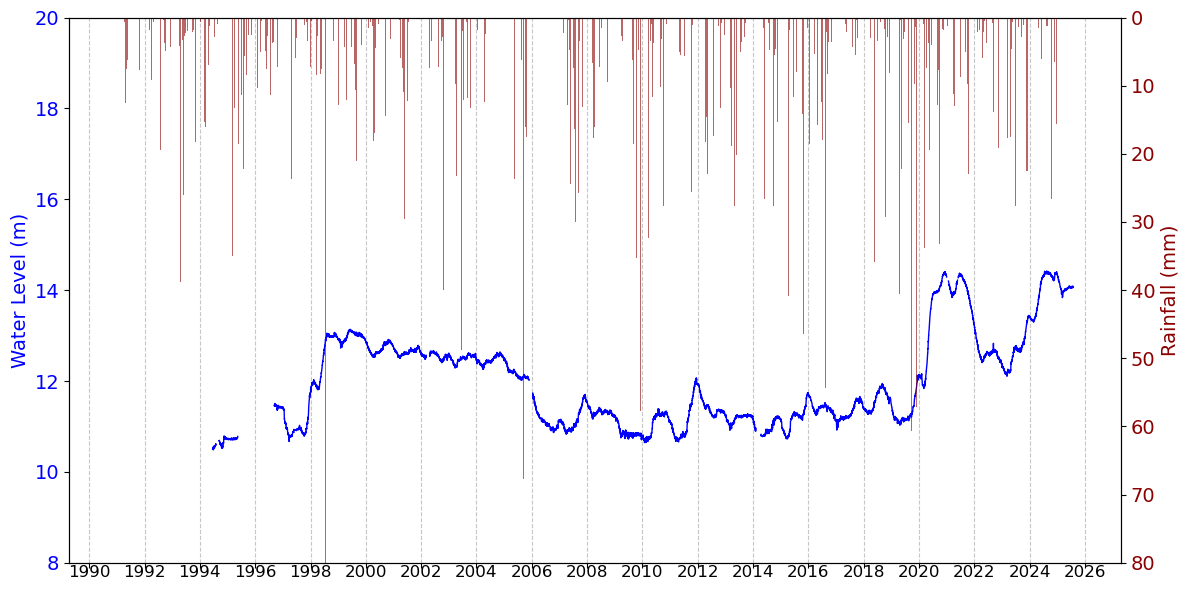

In [92]:
# --- Filter from 1990-01-01 ---
Bu_filtered = Bu[Bu['Date'] >= "1990-01-01"]
import matplotlib.dates as mdates
Bu['Date'] = pd.to_datetime(Bu['Date'])
# --- Plot ---
fig, ax1 = plt.subplots(figsize=(12,6))

# Water level on primary (left) axis
ax1.plot(Bu_filtered['Date'], Bu_filtered['Water level(m)'], 
         color='blue', linewidth=1, label="Water Level")
ax1.set_ylabel("Water Level (m)", color='blue', fontsize=14)
ax1.tick_params(axis='y', labelcolor='blue', labelsize=14)
ax1.set_ylim(8, 20)   # set limits for water level axis

# Rainfall on secondary (right) axis
ax2 = ax1.twinx()
ax2.bar(Bu_filtered['Date'], Bu_filtered['Rainfall (mm)'], 
        color='darkred', alpha=0.6, label="Rainfall")
ax2.set_ylabel("Rainfall (mm)", color='darkred', fontsize=14)
ax2.tick_params(axis='y', labelcolor='darkred', labelsize=14)
ax2.invert_yaxis()    # invert rainfall axis
ax2.set_ylim(80, 0) 
ax1.xaxis.set_major_locator(mdates.YearLocator(2))   # yearly ticks
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))  # show year
ax1.grid(True, which='major', axis='x', linestyle='--', alpha=0.7) 
# Force vertical alignment and make room
ax1.tick_params(axis='x', which='major', labelsize=12)
plt.setp(ax1.get_xticklabels(), rotation=0, ha='center', va='center')

# ensure labels don't get cropped
plt.subplots_adjust(bottom=0.18)

plt.xticks(rotation=90, ha='center')
fig.tight_layout()
plt.savefig('bugondo_station_plot.png', dpi=300, bbox_inches='tight')
plt.show()

In [73]:
Aw = pd.read_excel('D:/AWMZ Library/Personal docs/CNST/SW_Data/Awoja Daily.xlsx')

In [74]:
Aw.head()

,Date,Water level(m),Rainfall (mm)
0,1994-05-01,NaN,0.6
1,1994-05-02,NaN,36
2,1994-05-03,NaN,0
3,1994-05-04,NaN,5.5
4,1994-05-05,NaN,0


In [75]:
Aw['Rainfall (mm)'] = pd.to_numeric(Aw['Rainfall (mm)'], errors='coerce')